# Appendix B: Feature Engineering

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer

In [2]:
df_raw = pd.read_csv("data/raw_data.csv")

df_raw.head()

,gamesPlayed,gamesStarted,minutesPlayed,twoPointersMade,twoPointersAttempted,threePointersMade,threePointersAttempted,offensiveRebounds,defensiveRebounds,totalRebounds,...,steals,turnovers,blocks,freeThrowsMade,freeThrowsAttempted,foulsDrawn,code,name,season,position
0,26.0,0.0,8.480128,0.1,0.4,0.1,0.9,0.2,0.3,0.5,...,0.2,0.4,0.1,0.3,0.4,0.4,007265,"KURUCS, ARTURS",2021,1
1,31.0,3.0,6.978495,0.2,0.5,0.8,2.2,0.0,0.4,0.4,...,0.1,0.2,0.0,0.0,0.1,0.4,004508,"OBST, ANDREAS",2021,1
2,25.0,20.0,10.805333,0.4,0.8,0.6,1.4,0.2,0.6,0.7,...,0.4,0.3,0.1,0.0,0.0,0.1,007338,"UZINSKII, DMITRII",2021,2
3,23.0,2.0,7.260870,0.7,1.4,0.1,0.5,0.2,0.5,0.7,...,0.3,0.7,0.0,0.2,0.3,0.6,011220,"ZIV, IFTAH",2021,1
4,26.0,3.0,12.396154,0.6,1.5,0.3,1.4,0.2,0.4,0.7,...,0.3,0.6,0.1,0.6,0.7,0.8,011204,"GRANT, JERIAN",2021,1


## Preprocessing

First we drop the rows with very little games (<10 per season) or minutes (<10 per game) played. These rows belong to coaches, for example.

In [3]:
df_filtered = df_raw[(df_raw["minutesPlayed"] >= 10) & (df_raw["gamesPlayed"] >= 10)].reset_index()
print(f"Dropped {len(df_raw) - len(df_filtered)} rows with not enough games/minutes played. Now {len(df_filtered)}.")

Dropped 46 rows with not enough games/minutes played. Now 927.


Next we compute the features from the raw statistics and put them into a new dataframe. Some features require median imputation as they include values such as nan and inf.

In [4]:
df = pd.DataFrame()

df["POS"] = df_filtered["position"]
df["code"] = df_filtered["code"]
df["3PAr"] = df_filtered["threePointersAttempted"] / ( df_filtered["twoPointersAttempted"] + 
            df_filtered["threePointersAttempted"] )
df["3Pr"] = df_filtered["threePointersMade"] / df_filtered["threePointersAttempted"]
df["2Pr"] = df_filtered["twoPointersMade"] / df_filtered["twoPointersAttempted"]
df["2P"] = df_filtered["twoPointersMade"] / df_filtered["minutesPlayed"] * 40
df["FD"] = df_filtered["foulsDrawn"] / df_filtered["minutesPlayed"] * 40
df["FTr"] = df_filtered["freeThrowsAttempted"] / ( df_filtered["twoPointersAttempted"] + 
            df_filtered["threePointersAttempted"] )
df["AST"] = df_filtered["assists"] / df_filtered["minutesPlayed"] * 40
df["TR"] = df_filtered["totalRebounds"] / df_filtered["minutesPlayed"] * 40
df["BLK"] = df_filtered["blocks"] / df_filtered["minutesPlayed"] * 40
df["AST/TO"] = df_filtered["assists"] / ( df_filtered["turnovers"] )

# convert EuroLeague's numerical labels into more interpretable ones
df["POS"] = df["POS"].map({1: "G", 2: "F", 3: "C"})

# replace AST/TO's infinite values with NaN and perform median imputation
df["AST/TO"] = df["AST/TO"].replace([np.inf, -np.inf], np.nan)
df["AST/TO"] = SimpleImputer(missing_values=np.nan, strategy='median').fit_transform(df[["AST/TO"]])

# perform median imputation for 3Pr as well since is has many NaNs
df["3Pr"] = SimpleImputer(missing_values=np.nan, strategy='median').fit_transform(df[["3Pr"]])

df.round(3).head()

,POS,code,3PAr,3Pr,2Pr,2P,FD,FTr,AST,TR,BLK,AST/TO
0,F,007338,0.636,0.429,0.500,1.481,0.370,0.000,1.111,2.591,0.370,1.000
1,G,011204,0.483,0.214,0.400,1.936,2.581,0.241,2.259,2.259,0.323,1.167
2,F,004761,0.750,0.333,0.333,0.900,1.499,0.028,1.799,2.699,0.000,3.000
3,F,006251,0.613,0.211,0.500,2.038,1.699,0.129,0.679,7.474,0.000,0.400
4,G,002969,0.667,0.286,0.571,2.983,1.119,0.119,1.119,1.119,0.000,1.000


## Pearson Correlation Heatmap

To examine the correlations between features and possibly find redundant features, we make a Pearson correlation matrix and visualize it as a heatmap.

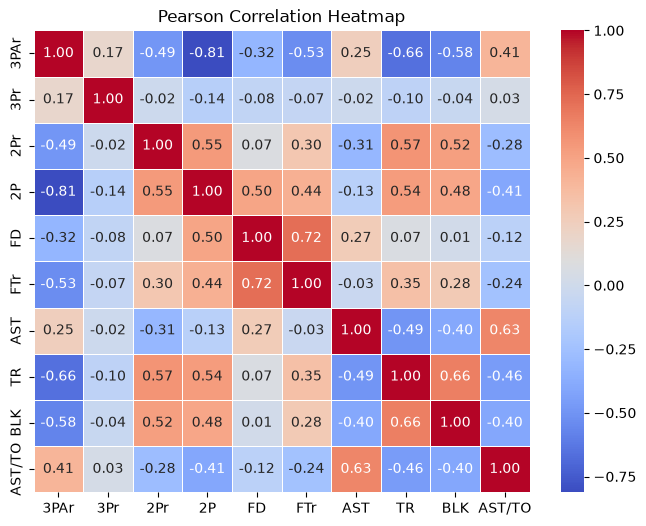

In [5]:
corr_matrix = df.drop(["POS", "code"], axis=1).corr() # make the correlation matrix

# visualize the matrix as a heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Pearson Correlation Heatmap")
plt.show()

In [6]:
# We drop FD due to the high correlation but keep 2P and 3PAr due to the difference in what they measure.
df = df.drop(columns=["FD"])

## Exploratory Data Analysis

Exploring the data. What does the data look like, and is there something that we should consider later on?

In [7]:
df.describe().round(2)

,3PAr,3Pr,2Pr,2P,FTr,AST,TR,BLK,AST/TO
count,927.00,927.00,927.00,927.00,927.00,927.00,927.00,927.00,927.00
mean,0.40,0.35,0.54,3.97,0.29,3.40,6.10,0.49,1.53
std,0.21,0.10,0.09,1.85,0.14,2.29,2.48,0.59,0.80
min,0.00,0.00,0.27,0.26,0.00,0.00,1.12,0.00,0.00
25%,0.28,0.32,0.49,2.59,0.19,1.70,4.09,0.13,1.00
50%,0.44,0.36,0.54,3.78,0.27,2.61,5.71,0.29,1.40
75%,0.55,0.39,0.60,5.05,0.37,4.56,7.82,0.67,2.00
max,0.93,1.00,0.89,10.04,0.96,12.31,13.89,3.52,7.50


What's noteworthy:
- total rebounds (TR) has a wide range of values (1.12 - 13.89) so it might be informative
- blocks (BLK) are heavily right-skewed, so maybe only a tiny chunk of players get lots of blocks

Let's look at the distributions of some interesting features and see how they relate to positions.

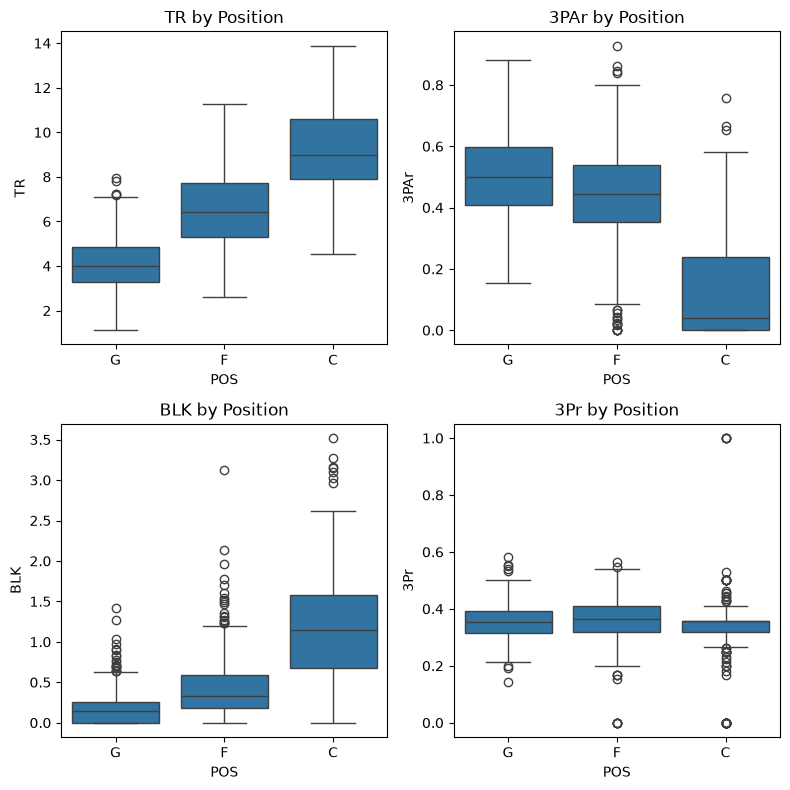

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.flatten()
order = ["G", "F", "C"]

sns.boxplot(data=df, x="POS", y="TR", order=order, ax=axes[0])
axes[0].set_title("TR by Position")

sns.boxplot(data=df, x="POS", y="3PAr", order=order, ax=axes[1])
axes[1].set_title("3PAr by Position")

sns.boxplot(data=df, x="POS", y="BLK", order=order, ax=axes[2])
axes[2].set_title("BLK by Position")

sns.boxplot(data=df, x="POS", y="3Pr", order=order, ax=axes[3])
axes[3].set_title("3Pr by Position")

plt.tight_layout()
# plt.savefig("visualizations/eda_boxplots.png")
plt.show()

- total rebounds (TR) seems to be a solid overall differentiator
- 3-pointer attempt rate (3PAr) seems to separate centers well
- the right-skewedness of blocks (BLK) is explained by mostly only centers having high values
- 3-pointer shooting accuracy seems to be similar for all positions

In [9]:
df["POS"].value_counts()

POS
G    379
F    354
C    194
Name: count, dtype: int64

The classes are imbalanced as there are almost twice as many guards and forwards than centers. This needs to be taken later on into account when splitting the data and training the models.

In [10]:
# write the processed DataFrame to csv
df.to_csv("data/processed_data.csv", index=False)